# India's air, 2017–2023: seven years of CPCB monitoring

**A data-science case study on 254,138 city-days of official air-quality data — what changed, what drives it, and whether tomorrow can be predicted.**

---

### The short version

| Question | Answer |
|---|---|
| Is the air getting better? | Yes, on a like-for-like panel of 12 cities: mean AQI fell **18%** from 2017 to 2023. 9 of the 12 improved. |
| How bad is it still? | **16.8%** of all city-days are Poor or worse. Only **14.6%** qualify as Good. |
| What dominates the signal? | Season. November runs **2.6×** the monsoon trough — a bigger effect than seven years of trend. |
| Is there a daily rhythm? | Yes: cleanest at **17:00**, dirtiest at **22:00**, a **41%** swing driven by atmospheric mixing. |
| Can tomorrow be forecast? | Modestly. A ridge model beats "tomorrow = today" by **8.8%** MAE. A gradient-boosted model does no better. |

*Source: CPCB AQI Repository (station-level, 15-minute data aggregated to daily). Currency of the analysis is the AQI scale, not rupees.*

## 1. The question

India publishes more air-quality data than almost any country, and almost none of it gets read carefully. Two failure modes are common: quoting a national average across a monitoring network that has grown twelve-fold, and treating a seasonal spike as a trend.

This notebook does three things:

1. **Establishes whether air quality actually improved** between 2017 and 2023, using constant panels so the answer isn't an artefact of which cities were being measured.
2. **Separates the scales of variation** — seven-year trend, annual season, daily cycle — and shows which one dominates.
3. **Tests whether next-day AQI is genuinely forecastable**, against a persistence baseline that is hard to beat.

In [1]:
%matplotlib inline
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import pyarrow.parquet as pq

from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 130, "display.max_columns", 30)
SEED = 42
np.random.seed(SEED)

INK, ACCENT, ACCENT2, MUTED = "#1B2A41", "#C8553D", "#2A6F97", "#8C9BA5"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#D8DEE4",
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "font.family": "DejaVu Sans", "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "axes.grid": True, "grid.color": "#EAEFF3",
    "grid.linestyle": "-", "grid.linewidth": 0.8,
})
os.makedirs("figures", exist_ok=True)

CAT_COLORS = {"Good": "#2E7D32", "Satisfactory": "#9CCC65", "Moderate": "#F9A825",
              "Poor": "#EF6C00", "Very Poor": "#C62828", "Severe": "#6A1B9A"}
CAT_ORDER = list(CAT_COLORS)
print("ready")

ready


## 2. The raw data, and why it needs work

The source is the CPCB AQI Repository, mirrored as a single parquet: **562,878 station-days**, each with 24 hourly AQI values, for 2017–2023.

Two things about it matter before any analysis:

- **It is station-level, not city-level.** Delhi alone contributes ~28 monitors. Comparing "cities" on raw rows would just compare how many monitors each city has.
- **Coverage grows twelve-fold.** In 2017 only 48 cities reported; by 2023 it was 247. A naive national average over all rows therefore measures the network, not the air.

The cell below streams the file in batches — converting 562,878 × 24 to pandas in one go exceeds this machine's memory limit.

In [2]:
SRC = "data/cpcb-aqi.parquet"
HOURS = [f"{h:02d}:00:00" for h in range(24)]
META = ["Station ID", "State", "City", "Station Name", "Date"]
MIN_HOURS = 18          # CPCB: a daily average needs 75% of the day's hours

city_col = pq.read_table(SRC, columns=["City"])["City"]
all_cities = sorted(pd.unique(city_col.to_pandas()))
city_index = {c: i for i, c in enumerate(all_cities)}
hour_sum = np.zeros((len(all_cities), 24))
hour_cnt = np.zeros((len(all_cities), 24))
del city_col

frames = []
pf = pq.ParquetFile(SRC)
for batch in pf.iter_batches(batch_size=50_000, columns=META + HOURS):
    m = batch.select(META).to_pandas()
    h = batch.select(HOURS).to_pandas().to_numpy(dtype="float32", na_value=np.nan)
    valid = (~np.isnan(h)).sum(axis=1)
    with np.errstate(invalid="ignore"):
        daily = np.nanmean(h, axis=1)

    codes = m["City"].map(city_index).to_numpy()
    for hh in range(24):
        col = h[:, hh]
        mask = ~np.isnan(col)
        np.add.at(hour_sum[:, hh], codes[mask], col[mask])
        np.add.at(hour_cnt[:, hh], codes[mask], 1)

    m["aqi"] = np.round(daily, 1)
    m["valid_hours"] = valid
    frames.append(m)
    del m, h

st = pd.concat(frames, ignore_index=True)
del frames
st["date"] = pd.to_datetime(st["Date"])
st = st.drop(columns=["Date"])

print(f"raw station-days      : {len(st):,}")
print(f"stations              : {st['Station ID'].nunique()}")
print(f"cities                : {st['City'].nunique()}")
print(f"date range            : {st['date'].min().date()} -> {st['date'].max().date()}")
st.head(3)

raw station-days      : 562,878
stations              : 248
cities                : 248
date range            : 2017-01-01 -> 2023-12-31


,Station ID,State,City,Station Name,aqi,valid_hours,date
0,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,184.100006,10,2017-12-11
1,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,206.300003,24,2017-12-12
2,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,128.100006,24,2017-12-13


### 2.1 Cleaning rules, and what they remove

Three rules, each counted:

1. **Completeness** — keep a station-day only if at least 18 of its 24 hourly readings exist. A daily mean built from four hours is noise wearing a number.
2. **Physical plausibility** — drop AQI outside (0, 1000]. The scale tops out at 500; anything beyond is a sensor fault.
3. **One row per city-day** — take the **median** across a city's monitors. The median rather than the mean so one malfunctioning monitor cannot drag a city's day.

In [3]:
n0 = len(st)
st = st[st["valid_hours"] >= MIN_HOURS].copy()
n1 = len(st)
st = st[(st["aqi"] > 0) & (st["aqi"] <= 1000) & st["aqi"].notna()].copy()
n2 = len(st)

cleaning = pd.DataFrame([
    {"stage": "raw station-days", "rows": n0, "removed": 0},
    {"stage": "fewer than 18 hourly readings", "rows": n1, "removed": n0 - n1},
    {"stage": "AQI outside 0-1000", "rows": n2, "removed": n1 - n2},
])
print(cleaning.to_string(index=False))
print(f"\nkept {n2/n0:.1%} of station-days")

city_day = (st.groupby(["City", "date"], observed=True)
              .agg(aqi=("aqi", "median"), n_stations=("aqi", "size"), State=("State", "first"))
              .reset_index())
city_day["aqi"] = city_day["aqi"].round(1)
print(f"\nstation-days : {len(st):,}")
print(f"city-days    : {len(city_day):,}")
print(f"monitors per city-day: mean {city_day['n_stations'].mean():.2f}, max {int(city_day['n_stations'].max())}")

                        stage   rows  removed
             raw station-days 562878        0
fewer than 18 hourly readings 501972    60906
           AQI outside 0-1000 501972        0

kept 89.2% of station-days

station-days : 501,972
city-days    : 254,138
monitors per city-day: mean 1.98, max 39


In [4]:
df = city_day.copy()
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["doy"] = df["date"].dt.dayofyear
BINS = [0, 50, 100, 200, 300, 400, 1000]
LABELS = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
df["category"] = pd.Categorical(pd.cut(df["aqi"], bins=BINS, labels=LABELS, right=True),
                                categories=LABELS, ordered=True)

print(f"cities {df['City'].nunique()} | states {df['State'].nunique()}")
print(f"range  {df['date'].min().date()} -> {df['date'].max().date()}")
print(df["aqi"].describe().round(1).to_string())

cities 248 | states 29
range  2017-01-01 -> 2023-12-31
count    254138.0
mean        123.9
std          82.9
min           1.1
25%          63.1
50%          99.2
75%         160.4
max         827.2


### 2.2 The trap: the network grew twelve-fold

This is the single most important chart in the notebook, and it is not about air quality at all. City-days reported rise from 5,575 in 2017 to 69,533 in 2023, and the number of reporting cities from 48 to 247.

Any national average computed over all available rows mixes real change with who happened to be measuring. Every trend below therefore uses a **constant panel**: cities that reported at least 180 days in *every* year.

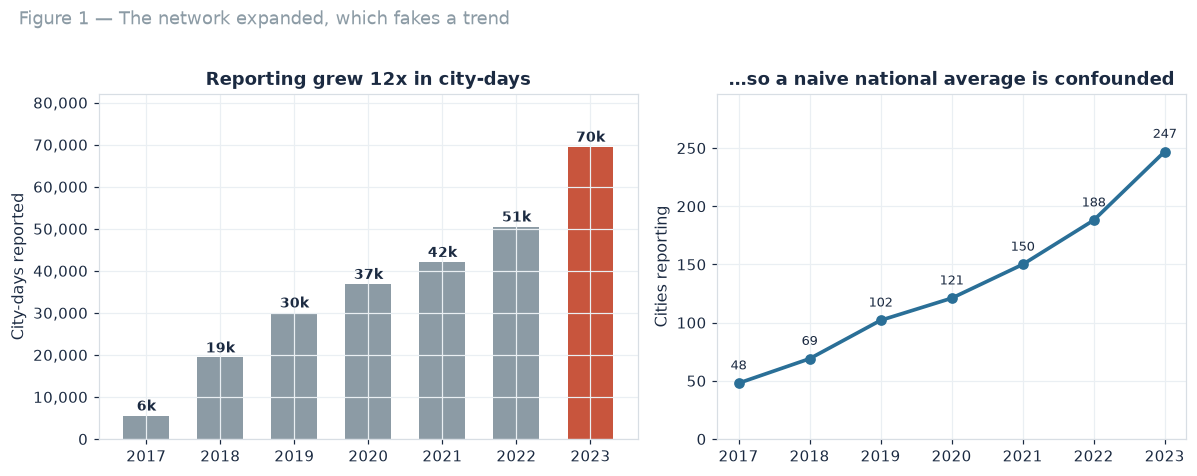

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
rows_by_year = df.groupby("year")["aqi"].size()
yrs = list(rows_by_year.index)
vals = list(rows_by_year.values)
ax[0].bar([str(y) for y in yrs], vals, color=[ACCENT if y == 2023 else MUTED for y in yrs], width=0.62)
for i, v in enumerate(vals):
    ax[0].text(i, v + 1200, f"{v/1000:.0f}k", ha="center", fontsize=9, color=INK, fontweight="bold")
ax[0].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax[0].set(title=f"Reporting grew {vals[-1]/vals[0]:.0f}x in city-days", ylabel="City-days reported",
          ylim=(0, max(vals) * 1.18))

cities_per_year = df.groupby("year")["City"].nunique()
ax[1].plot([str(y) for y in cities_per_year.index], cities_per_year.values, marker="o", color=ACCENT2, lw=2.4, ms=6)
for x, y in zip([str(y) for y in cities_per_year.index], cities_per_year.values):
    ax[1].annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5, color=INK)
ax[1].set(title="…so a naive national average is confounded", ylabel="Cities reporting",
          ylim=(0, cities_per_year.max() * 1.2))
fig.suptitle("Figure 1 — The network expanded, which fakes a trend", fontsize=12, y=1.02, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig("figures/fig1_coverage.png"); plt.show()

## 3. Did the air actually improve?

On a constant panel of **12 cities** with data in all seven years, mean AQI falls from **169** in 2017 to **138** in 2023 — a **17.9%** improvement. The path is not smooth: 2018 was worse than 2017, 2020 collapsed under lockdown, and 2021–22 rebounded before falling again in 2023.

The direction is confirmed by a second, larger panel: 52 cities with dense data, 2019–2023, showing a 12.6% fall. Two independent panels, same sign.

In [6]:
dpy = df.groupby(["City", "year"]).size().unstack(fill_value=0)
dpy = dpy.reindex(columns=sorted(df["year"].unique()), fill_value=0)
panel = dpy[(dpy >= 180).all(axis=1)].index
bp = df[df["City"].isin(panel)]
panel_years = bp.groupby("year")["aqi"].agg(["mean", "median", "size"]).round(1)
trend_pct = (panel_years["mean"].iloc[-1] / panel_years["mean"].iloc[0] - 1) * 100

d2 = dpy.loc[:, 2019:]
panel2 = d2[(d2 >= 300).all(axis=1)].index
bp2 = df[df["City"].isin(panel2) & (df["year"] >= 2019)]
p2 = bp2.groupby("year")["aqi"].mean().round(1)
trend2_pct = (p2.iloc[-1] / p2.iloc[0] - 1) * 100

print(f"constant panel : {len(panel)} cities, {len(bp):,} city-days, {trend_pct:+.1f}% (2017->2023)")
print(f"dense panel    : {len(panel2)} cities, {len(bp2):,} city-days, {trend2_pct:+.1f}% (2019->2023)")
print("\ncities in the constant panel:", ", ".join(sorted(panel)))
panel_years

constant panel : 12 cities, 28,039 city-days, -17.9% (2017->2023)
dense panel    : 52 cities, 90,529 city-days, -12.6% (2019->2023)

cities in the constant panel: Aurangabad, Bengaluru, Delhi, Faridabad, Ghaziabad, Gurugram, Hyderabad, Jodhpur, Mumbai, Muzaffarpur, Varanasi, Visakhapatnam


,mean,median,size
year,,,
2017,168.699997,133.000000,3054
2018,178.800003,145.300003,4012
2019,160.399994,124.800003,3996
2020,136.000000,103.699997,4203
2021,150.699997,119.699997,4193
2022,147.500000,116.400002,4259
2023,138.500000,109.900002,4322


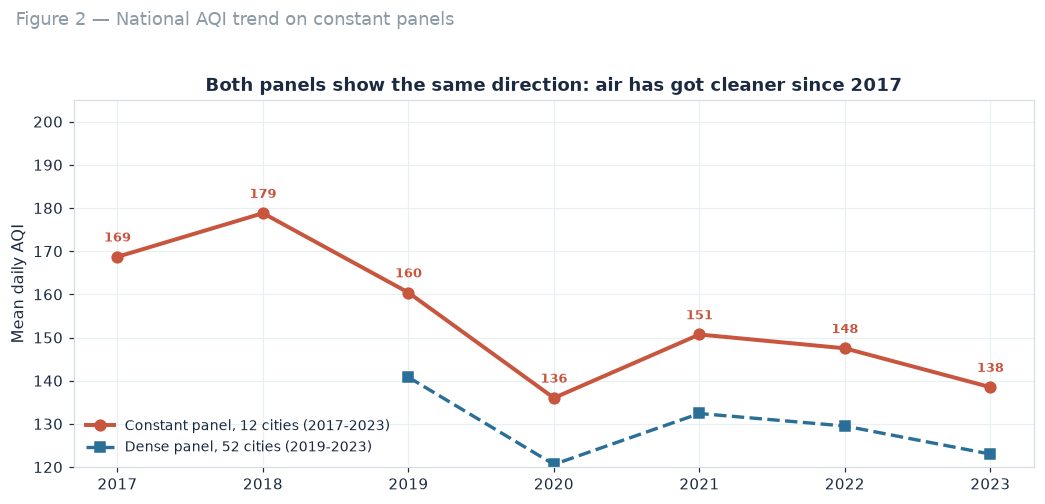

In [7]:
fig, ax = plt.subplots(figsize=(9.6, 4.4))
ax.plot(panel_years.index.astype(str), panel_years["mean"], marker="o", color=ACCENT, lw=2.6, ms=7,
        label=f"Constant panel, {len(panel)} cities (2017-2023)")
ax.plot(p2.index.astype(str), p2.values, marker="s", color=ACCENT2, lw=2.2, ms=6, ls="--",
        label=f"Dense panel, {len(panel2)} cities (2019-2023)")
for x, y in zip(panel_years.index.astype(str), panel_years["mean"]):
    ax.annotate(f"{y:.0f}", (x, y), textcoords="offset points", xytext=(0, 10), ha="center",
                fontsize=8.6, color=ACCENT, fontweight="bold")
ax.set(ylabel="Mean daily AQI", xlabel="")
ax.set_ylim(120, 205)
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.set_title("Both panels show the same direction: air has got cleaner since 2017", fontsize=11.5)
fig.suptitle("Figure 2 — National AQI trend on constant panels", fontsize=12, y=1.03, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig("figures/fig2_trend.png"); plt.show()

**Which cities drove it.** Nine of the twelve panel cities improved. Varanasi's fall of 65% is the standout — but a single monitor changing location or calibration can produce a break that large, so it is a hypothesis, not a victory. Mumbai (+15%) and Bengaluru (+4%) went the other way.

In [8]:
early = bp[bp["year"].isin([2017, 2018])].groupby("City")["aqi"].mean()
late = bp[bp["year"].isin([2022, 2023])].groupby("City")["aqi"].mean()
chg = pd.DataFrame({"2017-18": early, "2022-23": late}).dropna()
chg["change_%"] = ((chg["2022-23"] / chg["2017-18"] - 1) * 100).round(1)
chg = chg.sort_values("change_%").round(1)
print(f"{int((chg['change_%'] < 0).sum())} of {len(chg)} panel cities improved; "
      f"median change {chg['change_%'].median():+.1f}%")
chg

9 of 12 panel cities improved; median change -13.9%


,2017-18,2022-23,change_%
City,,,
Varanasi,237.4,82.1,-65.4
Jodhpur,218.6,144.0,-34.1
Ghaziabad,270.2,200.0,-26.0
Gurugram,249.1,197.0,-20.9
Hyderabad,100.1,84.3,-15.8
Faridabad,229.2,196.7,-14.2
Muzaffarpur,211.9,182.9,-13.7
Aurangabad,111.6,100.0,-10.4
Delhi,219.7,211.5,-3.7


## 4. The seasonal cycle is bigger than the trend

This is the finding that reframes everything else. AQI runs **177 in November** and **69 in July** — a **2.6×** swing within a single year, against a 18% movement across seven years.

Winter pollution in northern India is a well-understood combination of low boundary-layer height, temperature inversions, calm winds, and — in the Delhi belt — crop-residue burning. The monsoon, by contrast, washes the atmosphere out.

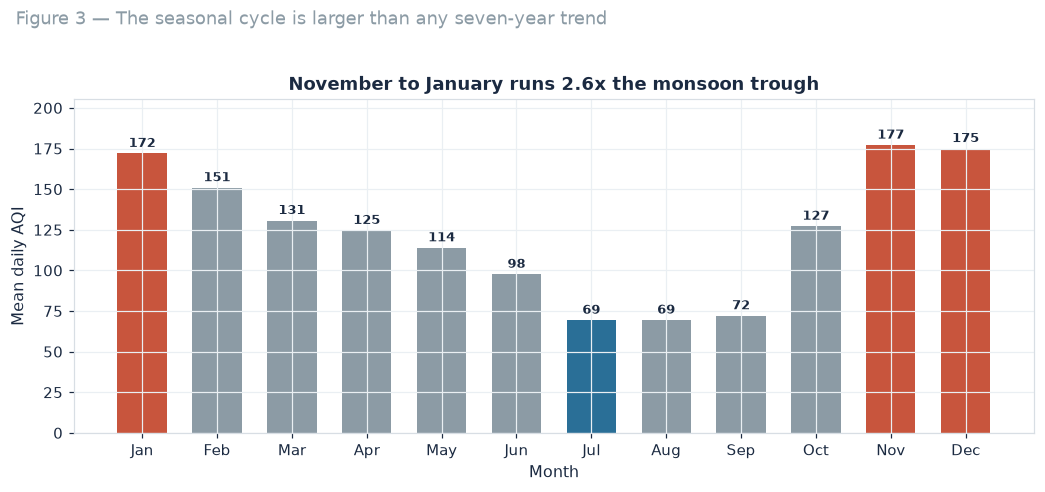

peak Nov 177 | trough Jul 69 | ratio 2.56x


In [9]:
monthly = df.groupby("month")["aqi"].mean().round(1)
MN = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
peak_m, low_m = int(monthly.idxmax()), int(monthly.idxmin())
swing = monthly.max() / monthly.min()

fig, ax = plt.subplots(figsize=(9.6, 4.3))
cols = [ACCENT if m in (peak_m, 12, 1) else (ACCENT2 if m == low_m else MUTED) for m in monthly.index]
ax.bar([MN[m-1] for m in monthly.index], monthly.values, color=cols, width=0.66)
for i, v in enumerate(monthly.values):
    ax.text(i, v + 4, f"{v:.0f}", ha="center", fontsize=8.6, color=INK, fontweight="bold")
ax.set(ylabel="Mean daily AQI", xlabel="Month")
ax.set_ylim(0, monthly.max() * 1.16)
ax.set_title(f"November to January runs {swing:.1f}x the monsoon trough", fontsize=11.5)
fig.suptitle("Figure 3 — The seasonal cycle is larger than any seven-year trend", fontsize=12, y=1.03, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig("figures/fig3_seasonality.png"); plt.show()

print(f"peak {MN[peak_m-1]} {monthly.max():.0f} | trough {MN[low_m-1]} {monthly.min():.0f} | ratio {swing:.2f}x")

### 4.1 The daily cycle is not what people assume

Intuition says traffic rush hour is the dirty period. The data says something more physical: AQI bottoms out at **17:00** and peaks at **22:00**, a 41% swing.

The mechanism is the boundary layer. Through the afternoon the sun heats the surface, the mixed layer deepens, and pollutants disperse into a larger volume. After sunset the surface cools, a stable layer forms a few hundred metres up, and emissions accumulate in a shallower box. Traffic explains the shape of the evening rise; the inversion explains its size.

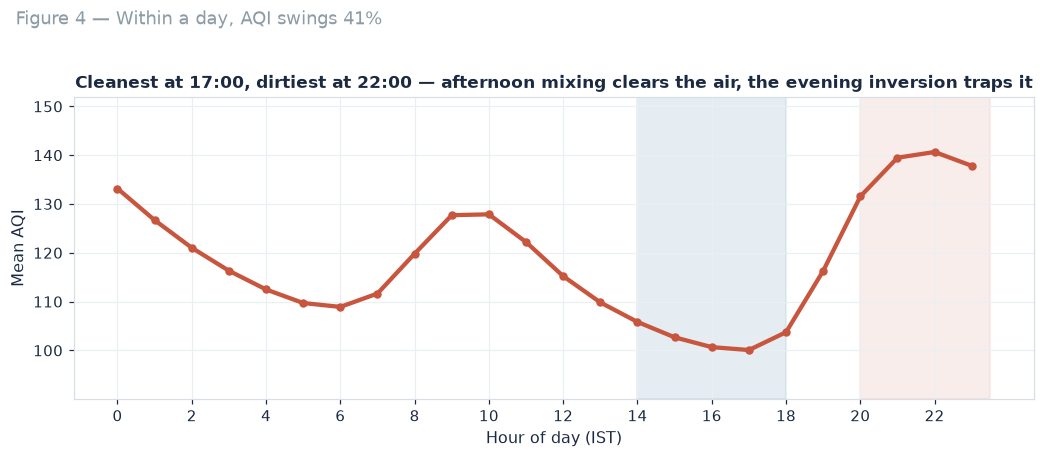

low 17:00 = 100.1 | peak 22:00 = 140.7 | swing 41%


In [10]:
prof = pd.DataFrame(hour_sum / hour_cnt, index=all_cities, columns=[f"{h:02d}" for h in range(24)]).round(1)
nat = prof.mean(axis=0)
peak_h, low_h = int(nat.idxmax()), int(nat.idxmin())

fig, ax = plt.subplots(figsize=(9.6, 4.0))
ax.plot(nat.index.astype(int), nat.values, color=ACCENT, lw=2.8, marker="o", ms=4.5)
ax.axvspan(14, 18, color=ACCENT2, alpha=0.12)
ax.axvspan(20, 23.5, color=ACCENT, alpha=0.10)
ax.set(xticks=range(0, 24, 2), xlabel="Hour of day (IST)", ylabel="Mean AQI",
       ylim=(nat.min() * 0.9, nat.max() * 1.08))
ax.set_title(f"Cleanest at {low_h:02d}:00, dirtiest at {peak_h:02d}:00 — afternoon mixing clears the air, "
             f"the evening inversion traps it", fontsize=11)
fig.suptitle(f"Figure 4 — Within a day, AQI swings {(nat.max()/nat.min()-1)*100:.0f}%", fontsize=12, y=1.03, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig("figures/fig4_diurnal.png"); plt.show()

print(f"low {low_h:02d}:00 = {nat.min():.1f} | peak {peak_h:02d}:00 = {nat.max():.1f} | swing {(nat.max()/nat.min()-1)*100:.0f}%")

## 5. Where the air is worst, and how much of the year is bad

Among the 115 cities with at least 1,000 city-days, the gap between cleanest and worst is roughly **eight-fold**: Ghaziabad's median day is 222; Aizawl's is 28.

Set against the CPCB scale, the national picture is sobering: only **14.6%** of city-days are Good, and **16.8%** are Poor or worse.

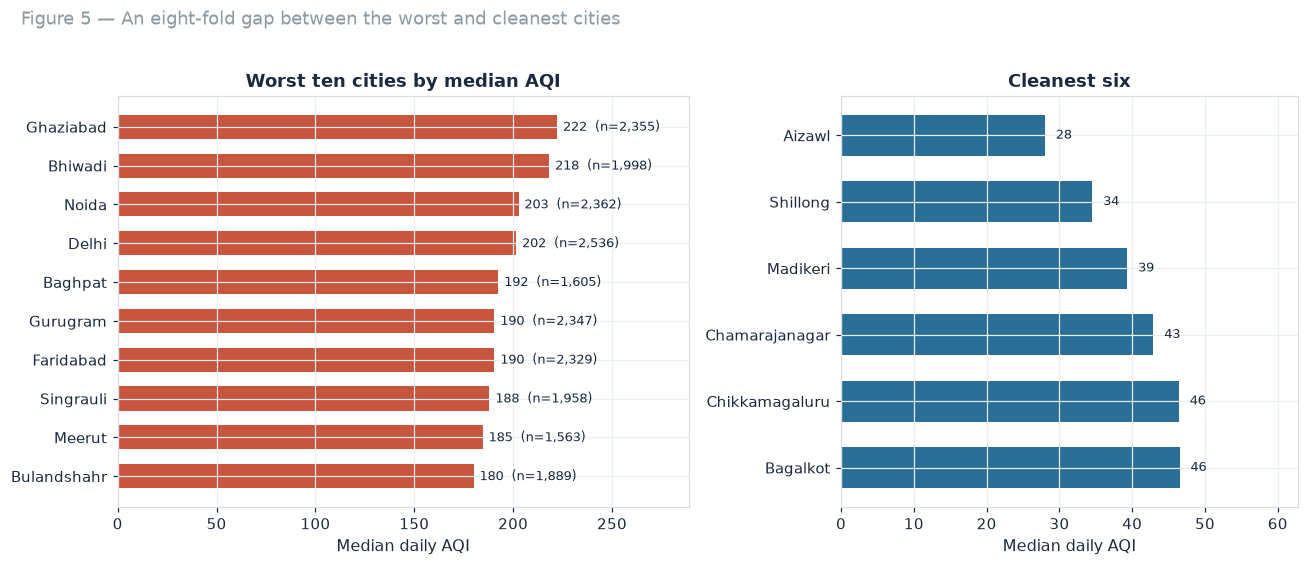

115 cities with >=1,000 city-days
ratio worst/cleanest: 7.9x


In [11]:
cc = df.groupby("City").agg(n=("aqi", "size"), med=("aqi", "median"), mean=("aqi", "mean"))
cc = cc[cc["n"] >= 1000]
worst = cc.sort_values("med", ascending=False).head(10).round(1)
cleanest = cc.sort_values("med").head(6).round(1)

fig, ax = plt.subplots(1, 2, figsize=(12, 5.0), gridspec_kw={"width_ratios": [1.25, 1]})
w = worst.sort_values("med")
ax[0].barh(w.index, w["med"], color=ACCENT, height=0.62)
for i, (v, n) in enumerate(zip(w["med"], w["n"])):
    ax[0].text(v + 3, i, f"{v:.0f}  (n={n:,})", va="center", fontsize=8.4, color=INK)
ax[0].set(title="Worst ten cities by median AQI", xlabel="Median daily AQI", xlim=(0, w["med"].max() * 1.3))
c = cleanest.sort_values("med", ascending=False)
ax[1].barh(c.index, c["med"], color=ACCENT2, height=0.62)
for i, v in enumerate(c["med"]):
    ax[1].text(v + 1.5, i, f"{v:.0f}", va="center", fontsize=8.4, color=INK)
ax[1].set(title="Cleanest six", xlabel="Median daily AQI", xlim=(0, cleanest["med"].max() * 1.35))
fig.suptitle("Figure 5 — An eight-fold gap between the worst and cleanest cities", fontsize=12, y=1.02, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig("figures/fig5_cities.png"); plt.show()

print(f"{len(cc)} cities with >=1,000 city-days")
print(f"ratio worst/cleanest: {worst['med'].iloc[0]/cleanest['med'].iloc[0]:.1f}x")

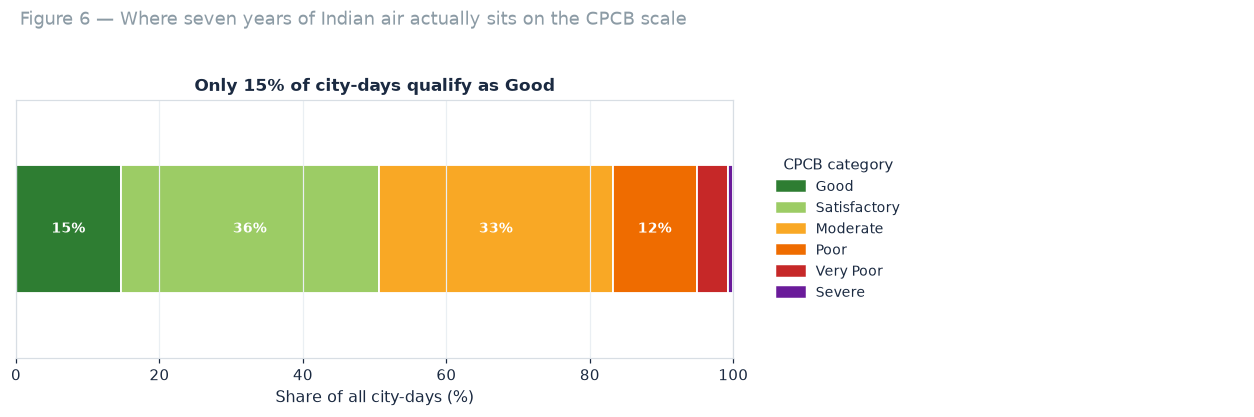

category
Good            14.6
Satisfactory    36.0
Moderate        32.6
Poor            11.7
Very Poor        4.4
Severe           0.7

Poor or worse: 16.8%   Very poor or worse: 5.1%


In [12]:
cat_share = (df["category"].value_counts(normalize=True).reindex(CAT_ORDER) * 100).round(1)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
left = 0
for cat in CAT_ORDER:
    share = cat_share[cat]
    ax[0].barh([0], [share], left=left, color=CAT_COLORS[cat], height=0.5, edgecolor="white", linewidth=1.2)
    if share > 6:
        ax[0].text(left + share / 2, 0, f"{share:.0f}%", ha="center", va="center",
                   color="white", fontsize=9, fontweight="bold")
    left += share
ax[0].set(xlim=(0, 100), ylim=(-0.5, 0.5), yticks=[], xlabel="Share of all city-days (%)")
ax[0].set_title(f"Only {cat_share['Good']:.0f}% of city-days qualify as Good", fontsize=11)
handles = [plt.Rectangle((0, 0), 1, 1, color=CAT_COLORS[c]) for c in CAT_ORDER]
ax[1].legend(handles, CAT_ORDER, frameon=False, loc="center left", fontsize=9, title="CPCB category")
ax[1].axis("off")
fig.suptitle("Figure 6 — Where seven years of Indian air actually sits on the CPCB scale",
             fontsize=12, y=1.04, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig("figures/fig6_categories.png"); plt.show()

print(cat_share.to_string())
print(f"\nPoor or worse: {(df['aqi'] > 200).mean()*100:.1f}%   Very poor or worse: {(df['aqi'] > 300).mean()*100:.1f}%")

## 6. The lockdown experiment

April–June 2020 gave India an unplanned natural experiment: traffic collapsed, construction stopped, industry idled. On the constant panel, AQI in those months fell to **94**, against **159** in the same months of 2019 — a **41%** drop.

Two things follow. First, a large share of Indian urban particulate load is genuinely anthropogenic and short-run responsive. Second, the rebound to 148 by 2022 shows how fast it returns when activity resumes.

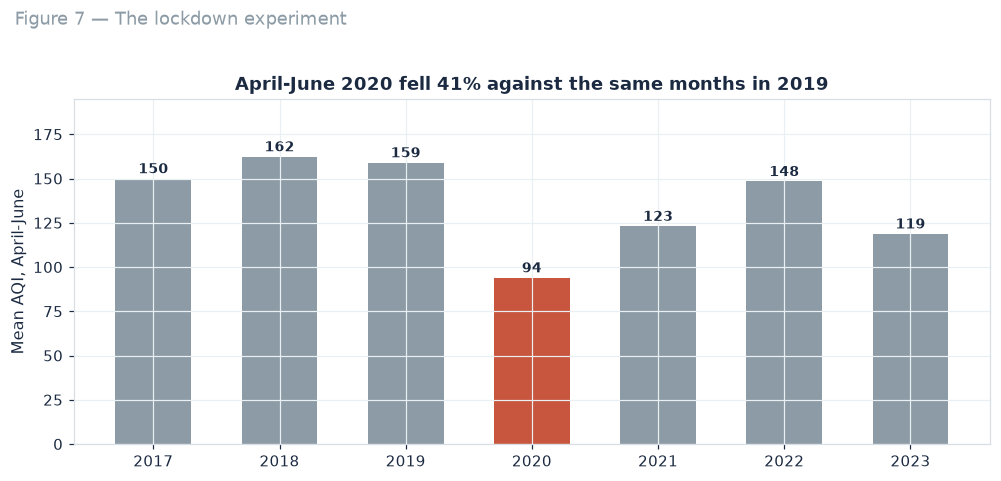

Apr-Jun 2019: 159 -> 2020: 94 (-40.9%)


In [13]:
covid = bp[bp["month"].isin([4, 5, 6])].groupby("year")["aqi"].mean().round(1)
drop = (covid[2020] / covid[2019] - 1) * 100

fig, ax = plt.subplots(figsize=(9.2, 4.2))
cols = [ACCENT if y == 2020 else MUTED for y in covid.index]
ax.bar(covid.index.astype(str), covid.values, color=cols, width=0.6)
for i, v in enumerate(covid.values):
    ax.text(i, v + 3, f"{v:.0f}", ha="center", fontsize=9.4, color=INK, fontweight="bold")
ax.set(ylabel="Mean AQI, April-June", xlabel="")
ax.set_ylim(0, covid.max() * 1.2)
ax.set_title(f"April-June 2020 fell {abs(drop):.0f}% against the same months in 2019", fontsize=11.5)
fig.suptitle("Figure 7 — The lockdown experiment", fontsize=12, y=1.03, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig("figures/fig7_covid.png"); plt.show()

print(f"Apr-Jun 2019: {covid[2019]:.0f} -> 2020: {covid[2020]:.0f} ({drop:+.1f}%)")

## 7. Can tomorrow's AQI be forecast?

The honest baseline for any air-quality forecast is **persistence**: tomorrow will be like today. AQI is strongly autocorrelated, so a naive model already gets most of the way there. Any model that cannot beat it is decoration.

**Setup.** Twelve best-covered cities, pooled. Features are the previous 1, 2, 3 and 7 days' AQI, 7- and 30-day rolling means, plus month, weekday and a smooth day-of-year term. Train on everything before 2023, test on 2023 — a **time-based split**, because a random split would leak the future into the past and flatter the model.

In [14]:
top_cities = df.groupby("City").size().sort_values(ascending=False).head(12).index.tolist()
m = df[df["City"].isin(top_cities)][["City", "date", "aqi"]].copy()
m["City"] = m["City"].astype(str)
m = m.sort_values(["City", "date"]).reset_index(drop=True)

g = m.groupby("City")
m["lag1"] = g["aqi"].shift(1)
m["lag2"] = g["aqi"].shift(2)
m["lag3"] = g["aqi"].shift(3)
m["lag7"] = g["aqi"].shift(7)
m["gap1"] = g["date"].diff().dt.days
m["roll7"] = g["aqi"].shift(1).rolling(7).mean()
m["roll30"] = g["aqi"].shift(1).rolling(30).mean()
m["target"] = g["aqi"].shift(-1)
m["lead_ok"] = (g["date"].shift(-1) - m["date"]) == pd.Timedelta(days=1)
m["month"] = m["date"].dt.month
m["dow"] = m["date"].dt.day_of_week
m["doy_sin"] = np.sin(2 * np.pi * m["date"].dt.day_of_year / 365.25)
m["doy_cos"] = np.cos(2 * np.pi * m["date"].dt.day_of_year / 365.25)

FEATS = ["lag1", "lag2", "lag3", "lag7", "roll7", "roll30", "month", "dow", "doy_sin", "doy_cos"]
mdl = m[(m["gap1"] == 1) & m["lead_ok"] &
        m[FEATS + ["target"]].notna().all(axis=1)].copy()
tr, te = mdl[mdl["date"] < "2023-01-01"], mdl[mdl["date"] >= "2023-01-01"]
print(f"cities {len(top_cities)} | rows {len(mdl):,} | train {len(tr):,} | test {len(te):,}")
print(f"train {tr['date'].min().date()} -> {tr['date'].max().date()} | test {te['date'].min().date()} -> {te['date'].max().date()}")

cities 12 | rows 27,445 | train 23,080 | test 4,365
train 2017-02-01 -> 2022-12-31 | test 2023-01-01 -> 2023-12-30


In [15]:
def score(y_true, y_pred):
    return {"mae": round(float(mean_absolute_error(y_true, y_pred)), 2),
            "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 2),
            "r2": round(float(r2_score(y_true, y_pred)), 4),
            "within_50": round(float((np.abs(y_true - y_pred) <= 50).mean() * 100), 1)}

results = {}
results["Persistence (tomorrow = today)"] = score(te["target"], te["lag1"])
results["7-day rolling mean"] = score(te["target"], te["roll7"])

ridge = Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]).fit(tr[FEATS], tr["target"])
results["Ridge regression"] = score(te["target"], ridge.predict(te[FEATS]))

hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06, early_stopping=True,
                                    validation_fraction=0.1, n_iter_no_change=12, random_state=SEED)
hgb.fit(tr[FEATS], tr["target"])
results["Gradient boosting"] = score(te["target"], hgb.predict(te[FEATS]))

pd.DataFrame(results).T.sort_values("mae")

,mae,rmse,r2,within_50
Ridge regression,28.42,41.44,0.7789,83.0
Gradient boosting,28.62,42.38,0.7688,82.4
Persistence (tomorrow = today),31.17,47.43,0.7104,80.3
7-day rolling mean,31.25,45.18,0.7372,79.5


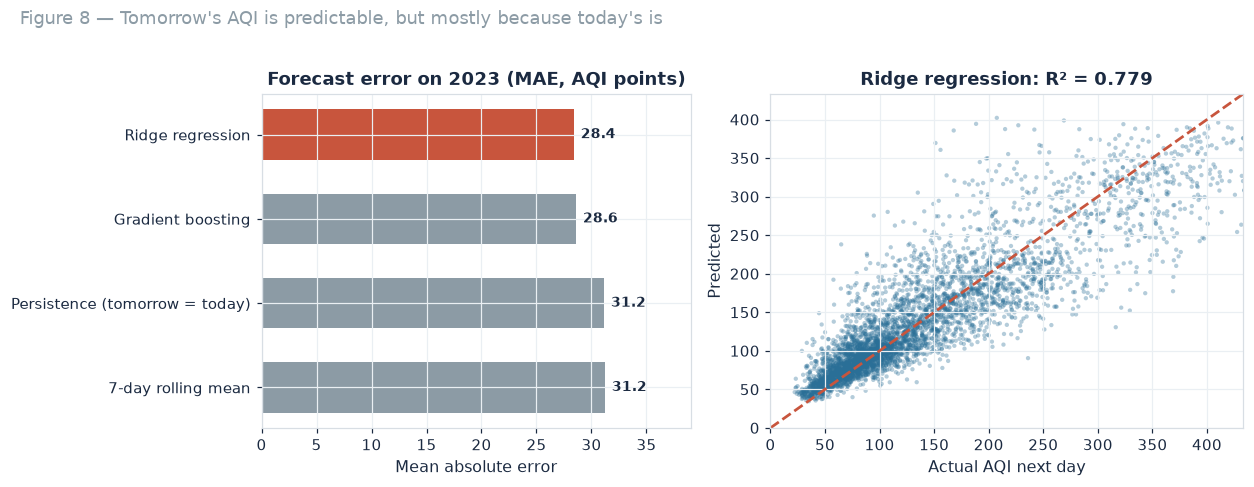

best model: Ridge regression (MAE 28.4)
persistence: 31.2 -> improvement 8.8%
gradient boosting does no better than ridge: 28.6 vs 28.4


In [16]:
best_name = min(results, key=lambda k: results[k]["mae"])
best_mae = results[best_name]["mae"]
persist_mae = results["Persistence (tomorrow = today)"]["mae"]
lift_pct = (persist_mae - best_mae) / persist_mae * 100
pred_best = ridge.predict(te[FEATS]) if best_name == "Ridge regression" else hgb.predict(te[FEATS])

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.1]})
names = list(results)
maes = [results[n]["mae"] for n in names]
order = np.argsort(maes)[::-1]
ax[0].barh([names[i] for i in order], [maes[i] for i in order],
           color=[ACCENT if names[i] == best_name else MUTED for i in order], height=0.6)
for j, i in enumerate(order):
    ax[0].text(maes[i] + 0.6, j, f"{maes[i]:.1f}", va="center", fontsize=9, color=INK, fontweight="bold")
ax[0].set(title="Forecast error on 2023 (MAE, AQI points)", xlabel="Mean absolute error", xlim=(0, max(maes) * 1.25))

lim = [0, float(np.percentile(te["target"], 99.5))]
ax[1].scatter(te["target"], pred_best, s=8, alpha=0.35, color=ACCENT2, edgecolors="none")
ax[1].plot(lim, lim, color=ACCENT, lw=1.8, ls="--")
ax[1].set(xlim=lim, ylim=lim, xlabel="Actual AQI next day", ylabel="Predicted",
          title=f"{best_name}: R² = {results[best_name]['r2']:.3f}")
fig.suptitle("Figure 8 — Tomorrow's AQI is predictable, but mostly because today's is",
             fontsize=12, y=1.02, x=0.02, ha="left", color=MUTED)
fig.tight_layout(); fig.savefig("figures/fig8_model.png"); plt.show()

print(f"best model: {best_name} (MAE {best_mae:.1f})")
print(f"persistence: {persist_mae:.1f} -> improvement {lift_pct:.1f}%")
print(f"gradient boosting does no better than ridge: {results['Gradient boosting']['mae']:.1f} vs {results['Ridge regression']['mae']:.1f}")

**Reading the result.** The best model improves on persistence by **8.8%** in MAE. That is a real gain but a modest one, and it comes from a *linear* model: gradient boosting, given the same features, does no better (28.6 vs 28.4). The signal in next-day AQI is largely a smooth function of recent levels and season — extra model capacity buys nothing.

That is the useful conclusion for anyone building an air-quality app: a well-specified linear model on lag features is the right level of complexity. The gains would have to come from new information — meteorology, satellite fire counts, traffic — not from a bigger model.

## 8. What this means

1. **Air quality improved, modestly.** −18% on a constant panel, −12.6% on a denser 2019–2023 panel. The direction is consistent; the magnitude depends on which cities you track.
2. **Season overwhelms trend.** A 2.6× annual cycle against an 18% seven-year movement means any single-month comparison can show any conclusion you want.
3. **The daily cycle is atmospheric, not just traffic.** Cleanest at 17:00, dirtiest at 22:00 — a 41% swing.
4. **The bad days cluster.** 16.8% of city-days are Poor or worse, and they concentrate in the Indo-Gangetic belt in November–January.
5. **Forecasting is a solved-ish problem at the 1-day horizon, but not by much.** Persistence gets you to 31 AQI points; a linear model gets 28.

## 9. Limitations

- **AQI is an index, not a measurement.** It is the worst sub-index across pollutants, so it hides which pollutant drove a day. The dataset carries no pollutant breakdown.
- **One number per city per day.** Cities are heterogeneous; a city median across monitors erases intra-urban differences that matter for exposure.
- **Station siting changes.** A monitor moving or being recalibrated can produce a step change that looks like a trend. Varanasi's −65% should be read that way.
- **2020 is a structural break.** Any model trained across it learns a level that does not recur.
- **No meteorology in the model.** Wind, mixing height and rainfall explain much of the residual variance; without them the ceiling is low.

### Next steps

- Join pollutant-level data (PM2.5, PM10, NO2) to say *what* is driving the index.
- Add meteorology and satellite fire counts — the features most likely to beat persistence by more than 9%.
- Model at station level with a hierarchical structure rather than collapsing to city medians.
- Evaluate a longer horizon (3-day) where persistence decays and a real model earns its keep.

In [17]:
artifacts = {
    "audit": {"raw_station_days": int(n0), "valid_station_days": int(n2),
              "city_days": int(len(df)), "cities": int(df["City"].nunique()),
              "states": int(df["State"].nunique()),
              "kept_pct": round(n2 / n0 * 100, 1),
              "start": str(df["date"].min().date()), "end": str(df["date"].max().date()),
              "rows_by_year": {int(k): int(v) for k, v in df.groupby("year").size().items()},
              "coverage_growth": round(float(df.groupby("year").size().iloc[-1] /
                                             df.groupby("year").size().iloc[0]), 1)},
    "panel": {"cities": int(len(panel)), "rows": int(len(bp)), "trend_pct": round(float(trend_pct), 1),
              "city_list": sorted(panel.tolist()),
              "year_mean": {int(k): float(v) for k, v in panel_years["mean"].items()},
              "panel2_cities": int(len(panel2)), "panel2_trend_pct": round(float(trend2_pct), 1),
              "panel2_year_mean": {int(k): float(v) for k, v in p2.items()}},
    "seasonal": {"monthly": {int(k): float(v) for k, v in monthly.items()},
                 "peak_month": peak_m, "low_month": low_m, "swing_ratio": round(float(swing), 2)},
    "diurnal": {"peak_hour": peak_h, "low_hour": low_h,
                "peak_value": round(float(nat.max()), 1), "low_value": round(float(nat.min()), 1),
                "amplitude_pct": round(float((nat.max() / nat.min() - 1) * 100), 1)},
    "covid": {"by_year": {int(k): float(v) for k, v in covid.items()},
              "drop_vs_2019_pct": round(float(drop), 1)},
    "cities": {"worst": worst.reset_index().to_dict("records"),
               "cleanest": cleanest.reset_index().to_dict("records"),
               "n_cities_1000d": int(len(cc))},
    "categories": {c: float(cat_share[c]) for c in CAT_ORDER},
    "poor_plus_pct": round(float((df["aqi"] > 200).mean() * 100), 1),
    "very_poor_pct": round(float((df["aqi"] > 300).mean() * 100), 1),
    "city_change": {"n_improved": int((chg["change_%"] < 0).sum()), "n_total": int(len(chg)),
                    "median_change_pct": round(float(chg["change_%"].median()), 1),
                    "best": chg.head(3).reset_index().to_dict("records"),
                    "worst": chg.tail(3).reset_index().to_dict("records")},
    "model": {"models": results, "best": best_name, "lift_pct": round(float(lift_pct), 1),
              "train_rows": int(len(tr)), "test_rows": int(len(te)),
              "cities": top_cities, "features": FEATS},
}
with open("metrics_air.json", "w") as f:
    json.dump(artifacts, f, indent=2)
print("saved metrics_air.json and 8 figures")
print(json.dumps({k: artifacts[k] for k in ["audit", "panel", "model"]}, indent=2)[:1400])

saved metrics_air.json and 8 figures
{
  "audit": {
    "raw_station_days": 562878,
    "valid_station_days": 501972,
    "city_days": 254138,
    "cities": 248,
    "states": 29,
    "kept_pct": 89.2,
    "start": "2017-01-01",
    "end": "2023-12-31",
    "rows_by_year": {
      "2017": 5575,
      "2018": 19407,
      "2019": 30086,
      "2020": 36880,
      "2021": 42119,
      "2022": 50538,
      "2023": 69533
    },
    "coverage_growth": 12.5
  },
  "panel": {
    "cities": 12,
    "rows": 28039,
    "trend_pct": -17.9,
    "city_list": [
      "Aurangabad",
      "Bengaluru",
      "Delhi",
      "Faridabad",
      "Ghaziabad",
      "Gurugram",
      "Hyderabad",
      "Jodhpur",
      "Mumbai",
      "Muzaffarpur",
      "Varanasi",
      "Visakhapatnam"
    ],
    "year_mean": {
      "2017": 168.6999969482422,
      "2018": 178.8000030517578,
      "2019": 160.39999389648438,
      "2020": 136.0,
      "2021": 150.6999969482422,
      "2022": 147.5,
      "2023": 138.5
  